# NYC Affordable Housing Production by Building

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset

In [2]:
housing = pd.read_csv("Affordable_Housing_Production_by_Building_20260830.csv")

## Initial Data Inspection

In [6]:
housing.head()

,Project ID,Project Name,Project Start Date,Project Completion Date,Building ID,Number,Street,Borough,Postcode,BBL,...,2-BR Units,3-BR Units,4-BR Units,5-BR Units,6-BR+ Units,Unknown-BR Units,Counted Rental Units,Counted Homeownership Units,All Counted Units,Total Units
0,75917,HOUSING PLUS. 729 VAN SINDEREN AVE.,03/31/2026,NaN,1014907.0,729,VAN SINDEREN AVENUE,Brooklyn,11207.0,NaN,...,40.0,NaN,NaN,NaN,NaN,NaN,193.0,NaN,193.0,193
1,76580,1692/1702/1706 UNION STREET.HUDMF.FY26,03/31/2026,03/31/2026,383416.0,1692,UNION STREET,Brooklyn,11213.0,3.014020e+09,...,16.0,8.0,NaN,NaN,NaN,NaN,45.0,NaN,45.0,45
2,76580,1692/1702/1706 UNION STREET.HUDMF.FY26,03/31/2026,03/31/2026,383420.0,1706,UNION STREET,Brooklyn,11213.0,3.014020e+09,...,10.0,4.0,NaN,NaN,NaN,NaN,16.0,NaN,16.0,16
3,77723,431 CONCORD AVENUE,03/31/2026,NaN,1018421.0,431,CONCORD AVENUE,Bronx,10455.0,2.025780e+09,...,57.0,NaN,NaN,NaN,NaN,NaN,141.0,NaN,141.0,142
4,78451,CONFIDENTIAL,03/31/2026,NaN,NaN,'----,'----,Brooklyn,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,3.0,3.0,3


In [5]:
housing.shape

(9250, 41)

In [6]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 9250 entries, 0 to 9249
Data columns (total 41 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Project ID                          9250 non-null   int64  
 1   Project Name                        9250 non-null   str    
 2   Project Start Date                  9250 non-null   str    
 3   Project Completion Date             7485 non-null   str    
 4   Building ID                         7382 non-null   float64
 5   Number                              9250 non-null   str    
 6   Street                              9250 non-null   str    
 7   Borough                             9250 non-null   str    
 8   Postcode                            7374 non-null   float64
 9   BBL                                 7305 non-null   float64
 10  BIN                                 7305 non-null   float64
 11  Community Board                     9250 non-null   st

## Data Quality Assessment

In [7]:
housing.isnull().sum()

Project ID                               0
Project Name                             0
Project Start Date                       0
Project Completion Date               1765
Building ID                           1868
Number                                   0
Street                                   0
Borough                                  0
Postcode                              1876
BBL                                   1945
BIN                                   1945
Community Board                          0
Council District                         1
Census Tract                          1876
NTA - Neighborhood Tabulation Area    1876
Latitude                              1876
Longitude                             1876
Latitude (Internal)                   1958
Longitude (Internal)                  1958
Building Completion Date              1619
Reporting Construction Type              0
Extended Affordability Only              0
Prevailing Wage Status                   0
Extremely L

In [8]:
missing_summary = pd.DataFrame({
    "missing_count": housing.isnull().sum(),
    "missing_pct": housing.isnull().mean() * 100
})

missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_pct", ascending=False)

,missing_count,missing_pct
6-BR+ Units,9224,99.718919
5-BR Units,9180,99.243243
4-BR Units,8697,94.021622
Unknown-BR Units,8598,92.951351
Other Income Units,7950,85.945946
Moderate Income Units,7647,82.670270
Extremely Low Income Units,7267,78.562162
Counted Homeownership Units,6609,71.448649
Middle Income Units,6569,71.016216
Studio Units,6137,66.345946


In [9]:
housing[["Project ID", "Building ID"]].duplicated().sum()

np.int64(0)

## Data Cleaning

In [10]:
date_columns = ["Project Start Date", "Project Completion Date", "Building Completion Date"]

for cols in date_columns:
    housing[cols] = pd.to_datetime(housing[cols], errors="coerce", format="%m/%d/%Y")

In [11]:
text_columns = housing.select_dtypes(include=["object", "string"]).columns

housing[text_columns] = housing[text_columns].replace("'----", np.nan, regex=True)

In [12]:
integer_columns = [
    "Project ID",
    "Building ID",
    "Postcode",
    "BBL",
    "BIN",
    "Council District",
    "Census Tract"
]

for col in integer_columns:
    housing[col] = pd.to_numeric(housing[col], errors="coerce").astype("Int64")

In [13]:
housing["Total Units"] = housing["Total Units"].str.replace(",", "").astype(float)

In [14]:
unit_columns = [
    "Extremely Low Income Units",
    "Very Low Income Units",
    "Low Income Units",
    "Moderate Income Units",
    "Middle Income Units",
    "Other Income Units",
    "Studio Units",
    "1-BR Units",
    "2-BR Units",
    "3-BR Units",
    "4-BR Units",
    "5-BR Units",
    "6-BR+ Units",
    "Unknown-BR Units",
    "Counted Rental Units",
    "Counted Homeownership Units",
    "All Counted Units",
    "Total Units"
]

housing[unit_columns] = housing[unit_columns].fillna(0)

- Missing values in unit-count fields are treated as zero for analysis because the bedroom and tenure breakdowns reconcile exactly with All Counted Units. Other missing values are retained because they represent unavailable information rather than zero.

## Post-Cleaning Validation

In [15]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 9250 entries, 0 to 9249
Data columns (total 41 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   Project ID                          9250 non-null   Int64         
 1   Project Name                        9250 non-null   str           
 2   Project Start Date                  9250 non-null   datetime64[us]
 3   Project Completion Date             7485 non-null   datetime64[us]
 4   Building ID                         7382 non-null   Int64         
 5   Number                              7382 non-null   str           
 6   Street                              7382 non-null   str           
 7   Borough                             9250 non-null   str           
 8   Postcode                            7374 non-null   Int64         
 9   BBL                                 7305 non-null   Int64         
 10  BIN                                

In [16]:
housing.isnull().sum()

Project ID                               0
Project Name                             0
Project Start Date                       0
Project Completion Date               1765
Building ID                           1868
Number                                1868
Street                                1868
Borough                                  0
Postcode                              1876
BBL                                   1945
BIN                                   1945
Community Board                          0
Council District                         1
Census Tract                          1876
NTA - Neighborhood Tabulation Area    1876
Latitude                              1876
Longitude                             1876
Latitude (Internal)                   1958
Longitude (Internal)                  1958
Building Completion Date              1619
Reporting Construction Type              0
Extended Affordability Only              0
Prevailing Wage Status                   0
Extremely L

In [17]:
unit_columns = [
    "Extremely Low Income Units",
    "Very Low Income Units",
    "Low Income Units",
    "Moderate Income Units",
    "Middle Income Units",
    "Other Income Units",
    "Studio Units",
    "1-BR Units",
    "2-BR Units",
    "3-BR Units",
    "4-BR Units",
    "5-BR Units",
    "6-BR+ Units",
    "Unknown-BR Units",
    "Counted Rental Units",
    "Counted Homeownership Units",
    "All Counted Units",
    "Total Units"
]

(housing[unit_columns] < 0).sum()

Extremely Low Income Units     0
Very Low Income Units          0
Low Income Units               0
Moderate Income Units          0
Middle Income Units            0
Other Income Units             0
Studio Units                   0
1-BR Units                     0
2-BR Units                     0
3-BR Units                     0
4-BR Units                     0
5-BR Units                     0
6-BR+ Units                    0
Unknown-BR Units               0
Counted Rental Units           0
Counted Homeownership Units    0
All Counted Units              0
Total Units                    0
dtype: int64

## Feature Engineering

In [18]:
housing["Affordable Unit Share"] = (
    housing["All Counted Units"]
    / housing["Total Units"]
    * 100
).round(2)

housing["Affordable Unit Share"].describe()

count    9250.000000
mean       81.567910
std        30.616267
min         0.000000
25%        42.860000
50%       100.000000
75%       100.000000
max       100.000000
Name: Affordable Unit Share, dtype: float64

## Exploratory Data Analysis

### EDA 1: Affordable Housing Production Over Time

In [119]:
housing["Project Start Year"] = housing["Project Start Date"].dt.year

yearly_production = housing.groupby("Project Start Year").agg(
    project_count = ("Project ID", "count"),
    affordable_units = ("All Counted Units", "sum")
)

yearly_production["avg_affordable_units_per_project"] = (
    yearly_production["affordable_units"] /
    yearly_production["project_count"]
)

yearly_production

,project_count,affordable_units,avg_affordable_units_per_project
Project Start Year,,,
2014,734,19629.0,26.742507
2015,695,21155.0,30.438849
2016,722,22344.0,30.947368
2017,703,24789.0,35.261735
2018,693,34823.0,50.249639
2019,821,25442.0,30.989038
2020,616,30170.0,48.977273
2021,791,27487.0,34.749684
2022,674,16465.0,24.428783


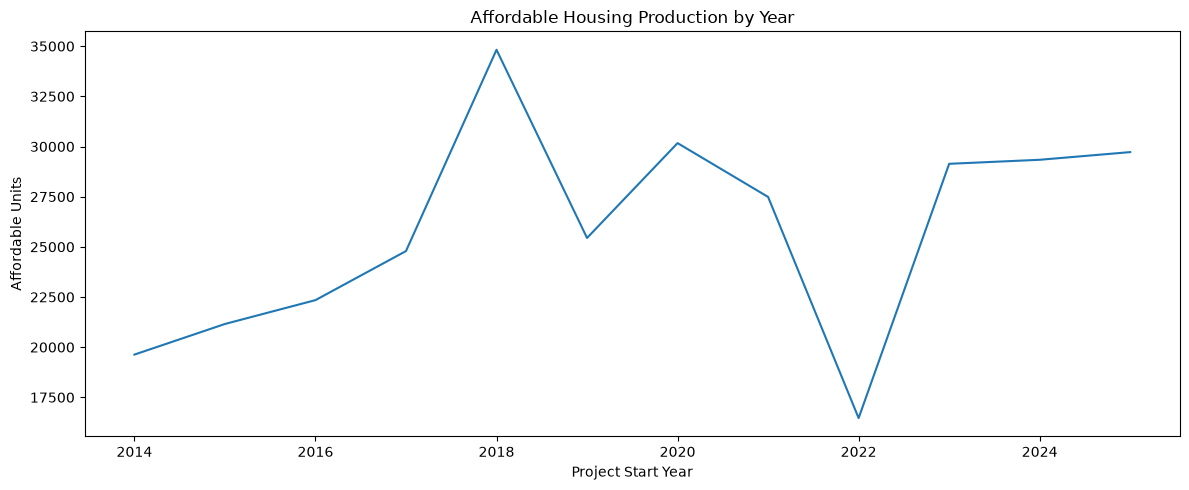

In [120]:
# Visualization
yearly_production_complete = yearly_production[yearly_production.index < 2026]

plt.figure(figsize=(12, 5))

plt.plot(
    yearly_production_complete.index,
    yearly_production_complete["affordable_units"]
)

plt.title("Affordable Housing Production by Year")
plt.xlabel("Project Start Year")
plt.ylabel("Affordable Units")

plt.tight_layout()
plt.show()

- Note: 2026 contains only partial-year data and should not be directly compared with completed years.

### EDA 2: Geographic Distribution

In [121]:
borough_analysis = housing.groupby("Borough").agg(
    project_count = ("Project ID", "count"),
    affordable_units = ("All Counted Units", "sum")
)

borough_analysis["affordable_unit_share_pct"] = (
    borough_analysis["affordable_units"] /
    borough_analysis["affordable_units"].sum()
    * 100
)

borough_analysis.sort_values("affordable_units", ascending=False)

,project_count,affordable_units,affordable_unit_share_pct
Borough,,,
Bronx,2502,102592.0,32.789987
Brooklyn,3593,89105.0,28.479334
Manhattan,1449,72504.0,23.173398
Queens,1268,42480.0,13.577264
Staten Island,438,6195.0,1.980018


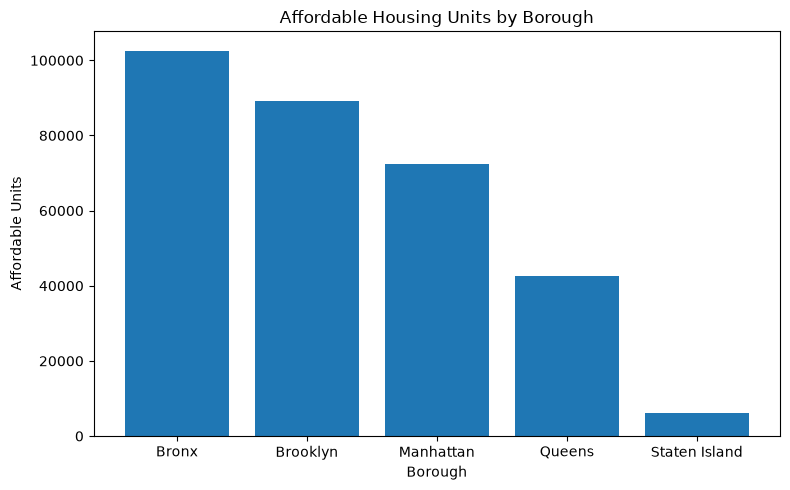

In [122]:
# Visualization
plt.figure(figsize=(8, 5))

plt.bar(
    borough_analysis.index,
    borough_analysis["affordable_units"]
)

plt.title("Affordable Housing Units by Borough")
plt.xlabel("Borough")
plt.ylabel("Affordable Units")

plt.tight_layout()
plt.show()

### EDA 3: New Construction vs Preservation

In [151]:
construction_analysis = housing.groupby("Reporting Construction Type").agg(
    project_count = ("Project ID", "count"),
    affordable_units = ("All Counted Units", "sum")
)

construction_analysis["affordable_unit_share_pct"] = (
    construction_analysis["affordable_units"] / 
    construction_analysis["affordable_units"].sum()
    * 100
)

construction_analysis["avg_affordable_units"] = (
    construction_analysis["affordable_units"] /
    construction_analysis["project_count"]
)

construction_analysis

,project_count,affordable_units,affordable_unit_share_pct,avg_affordable_units
Reporting Construction Type,,,,
New Construction,4674,127899.0,40.878495,27.363928
Preservation,4576,184977.0,59.121505,40.423295


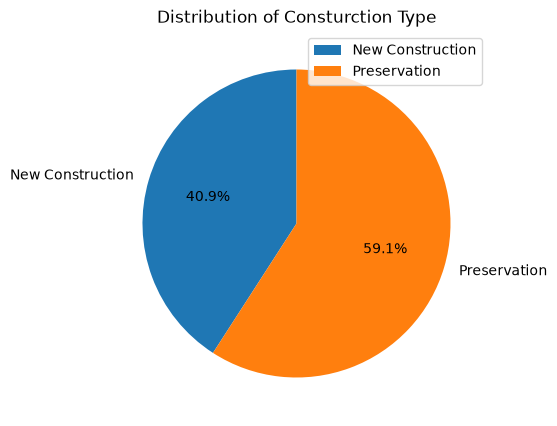

In [124]:
# Visualization
plt.figure(figsize=(8, 5))

plt.pie(
    construction_analysis["affordable_units"],
    labels = construction_analysis.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Distribution of Consturction Type")
plt.legend()
plt.show()

### EAD 4: Income composition

In [125]:
income_columns = [
    "Extremely Low Income Units",
    "Very Low Income Units",
    "Low Income Units",
    "Moderate Income Units",
    "Middle Income Units",
    "Other Income Units"
]

income_totals = housing[income_columns].sum().sort_values(ascending=False)

income_share = (income_totals / income_totals.sum() * 100)

income_analysis = pd.DataFrame({
    "units": income_totals,
    "share_pct": income_share
})

income_analysis

,units,share_pct
Low Income Units,106478.0,34.032013
Very Low Income Units,83998.0,26.847058
Extremely Low Income Units,56232.0,17.972615
Middle Income Units,45650.0,14.590445
Moderate Income Units,19181.0,6.130544
Other Income Units,1337.0,0.427326


### EDA 5: Bedroom composition

In [128]:
bedroom_columns = [
    "Studio Units",
    "1-BR Units",
    "2-BR Units",
    "3-BR Units",
    "4-BR Units",
    "5-BR Units",
    "6-BR+ Units",
    "Unknown-BR Units"
]

bedroom_totals = housing[bedroom_columns].sum().sort_values(ascending=False)

bedroom_share = (bedroom_totals / bedroom_totals.sum() * 100)

bedroom_analysis = pd.DataFrame({
    "units": bedroom_totals,
    "share_pct": bedroom_share
})

bedroom_analysis

,units,share_pct
1-BR Units,113551.0,36.292653
2-BR Units,103423.0,33.055588
Studio Units,54433.0,17.397627
3-BR Units,34702.0,11.091295
Unknown-BR Units,3643.0,1.164359
4-BR Units,2837.0,0.906749
5-BR Units,193.0,0.061686
6-BR+ Units,94.0,0.030044


### EDA 6: Project Size

In [129]:
project_size = housing.groupby("Project ID").agg(
    affordable_units = ("All Counted Units", "sum"),
    total_units = ("Total Units", "sum")
)

project_size.describe()

,affordable_units,total_units
count,5772.000000,5772.000000
mean,54.205821,75.514900
std,270.574769,283.842273
min,1.000000,1.000000
25%,1.000000,1.000000
50%,6.000000,16.000000
75%,43.000000,71.000000
max,15372.000000,15372.000000


In [130]:
project_size["affordable_unit_share_pct"] = (
    project_size["affordable_units"] /
    project_size["total_units"]
    * 100
)

project_size["affordable_unit_share_pct"].describe()

count    5772.000000
mean       72.354493
std        33.897565
min         0.763359
25%        31.818182
50%       100.000000
75%       100.000000
max       100.000000
Name: affordable_unit_share_pct, dtype: float64

### EDA 7: Affordable Unit Share

In [131]:
housing["Affordability Category"] = pd.cut(
    housing["Affordable Unit Share"],
    bins=[-0.01, 0, 50, 99.999, 100],
    labels=[
        "No Affordable Units",
        "Mostly Market-Rate",
        "Mixed Affordability",
        "Fully Affordable"
    ]
)

affordability_category = housing["Affordability Category"].value_counts().sort_index()

affordability_category

Affordability Category
No Affordable Units      28
Mostly Market-Rate     2349
Mixed Affordability     370
Fully Affordable       6503
Name: count, dtype: int64

### EDA 8: Project Duration

In [132]:
completed = housing[housing["Project Completion Date"].notna()].copy()

completed["Project Duration Years"] = (
    completed["Project Completion Date"] -
    completed["Project Start Date"]
).dt.days / 365.25

completed = completed[completed["Project Duration Years"] >= 0]

In [133]:
duration_by_construction = completed.groupby("Reporting Construction Type").agg(
    project_count = ("Project ID", "count"),
    median_duration_years = ("Project Duration Years", "median"),
    avg_duration_years = ("Project Duration Years", "mean")
)

duration_by_construction

,project_count,median_duration_years,avg_duration_years
Reporting Construction Type,,,
New Construction,3854,0.733744,1.185037
Preservation,3626,0.603696,1.471268


In [134]:
duration_by_borough = completed.groupby("Borough").agg(
    project_count = ("Project ID", "count"),
    median_duration_years = ("Project Duration Years", "median"),
    avg_duration_years = ("Project Duration Years", "mean")
)

duration_by_borough

,project_count,median_duration_years,avg_duration_years
Borough,,,
Bronx,1997,0.728268,1.272363
Brooklyn,2974,0.996578,1.609325
Manhattan,1155,0.741958,1.355848
Queens,1009,0.336756,0.934098
Staten Island,345,0.000000,0.192459


## Export Cleaned Data

In [21]:
housing.to_csv("nyc_affordable_housing_cleaned.csv", index=False)

In [19]:
housing

,Project ID,Project Name,Project Start Date,Project Completion Date,Building ID,Number,Street,Borough,Postcode,BBL,...,3-BR Units,4-BR Units,5-BR Units,6-BR+ Units,Unknown-BR Units,Counted Rental Units,Counted Homeownership Units,All Counted Units,Total Units,Affordable Unit Share
0,75917,HOUSING PLUS. 729 VAN SINDEREN AVE.,2026-03-31,NaT,1014907,729,VAN SINDEREN AVENUE,Brooklyn,11207,<NA>,...,0.0,0.0,0.0,0.0,0.0,193.0,0.0,193.0,193.0,100.0
1,76580,1692/1702/1706 UNION STREET.HUDMF.FY26,2026-03-31,2026-03-31,383416,1692,UNION STREET,Brooklyn,11213,3014020029,...,8.0,0.0,0.0,0.0,0.0,45.0,0.0,45.0,45.0,100.0
2,76580,1692/1702/1706 UNION STREET.HUDMF.FY26,2026-03-31,2026-03-31,383420,1706,UNION STREET,Brooklyn,11213,3014020036,...,4.0,0.0,0.0,0.0,0.0,16.0,0.0,16.0,16.0,100.0
3,77723,431 CONCORD AVENUE,2026-03-31,NaT,1018421,431,CONCORD AVENUE,Bronx,10455,2025780015,...,0.0,0.0,0.0,0.0,0.0,141.0,0.0,141.0,142.0,99.3
4,78451,CONFIDENTIAL,2026-03-31,NaT,<NA>,NaN,NaN,Brooklyn,<NA>,<NA>,...,0.0,0.0,0.0,0.0,3.0,0.0,3.0,3.0,3.0,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9245,55697,CONFIDENTIAL,2014-01-14,2014-01-14,<NA>,NaN,NaN,Brooklyn,<NA>,<NA>,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,100.0
9246,55773,CONFIDENTIAL,2014-01-10,2014-01-10,<NA>,NaN,NaN,Staten Island,<NA>,<NA>,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,100.0
9247,57341,CONFIDENTIAL,2014-01-10,2014-01-10,<NA>,NaN,NaN,Staten Island,<NA>,<NA>,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,100.0
9248,55647,CONFIDENTIAL,2014-01-07,2014-01-07,<NA>,NaN,NaN,Brooklyn,<NA>,<NA>,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,100.0


In [20]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 9250 entries, 0 to 9249
Data columns (total 42 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   Project ID                          9250 non-null   Int64         
 1   Project Name                        9250 non-null   str           
 2   Project Start Date                  9250 non-null   datetime64[us]
 3   Project Completion Date             7485 non-null   datetime64[us]
 4   Building ID                         7382 non-null   Int64         
 5   Number                              7382 non-null   str           
 6   Street                              7382 non-null   str           
 7   Borough                             9250 non-null   str           
 8   Postcode                            7374 non-null   Int64         
 9   BBL                                 7305 non-null   Int64         
 10  BIN                                